# EC442 Macroeconomics for MRes students

LSE, Autumn 2026 · Instructor: Matthias Doepke · Class notebook by Enrico D. Turri (e.turri@lse.ac.uk)

# Problem Set 3, Questions 1 and 3

**This notebook:**
- **Question 1:** solve the standard growth model by approximating the solution by *polynomial interpolation*
- **Question 3:** solve the $AK$ model with endogenous labour supply by VFI on a grid
- **Beyond the problem set:** why polynomials of odd degree go wrong in Question 1

## Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial import polynomial as P

# some useful plot defaults
plt.rcParams.update({'font.size': 12, 'lines.linewidth': 2, 'figure.figsize': (7, 3.5),
                     'axes.spines.top': False, 'axes.spines.right': False})

## The problem

Same Bellman equation as in Problem Set 2:

$$
v(k)=\max_{k'\geq 0}\Big\{\log\big((1-\delta)k+Ak^\alpha-k'\big)+\beta\, v(k')\Big\} \tag{1}
$$

- Parameters: $\beta=0.9$, $A=3$, $\alpha=0.3$, $\delta=0.2$
- Nodes in the interval $[1,10]$; plots on $[0,15]$
- Benchmark: Howard's algorithm from Problem Set 2, on a grid that extends to $15$

As in Problem Set 2, all parameters are stored in one dictionary, `params`, which every function takes as an input

In [2]:
params = dict(beta=0.9, A=3.0, alpha=0.3, delta=0.2,   # model parameters
              k_min=1.0, k_max=10.0,                   # interval for the nodes
              k_plot=15.0)                             # upper bound for plots and for the benchmark grid

def resources(k, params):
    return (1 - params['delta'])*k + params['A']*k**params['alpha']    # resources available for c + k'

# Question 1

## Q1.0 Value function iteration with polynomials

In Problem Set 2, $v$ was described by its values at $N=10{,}000$ grid points. Now we describe it by the $n+1$ coefficients of a polynomial
$$
v(k)=\sum_{i=0}^n a_i k^i \tag{2}
$$
and iterate on the coefficients. Five steps:
1. **Choose the nodes:** $n+1$ points $K=\{\kappa_0,\dots,\kappa_n\}$ in $[1,10]$
2. **Start from a guess** $a_{i,0}=0$ for all $i$, that is $v_0=0$
3. **Apply the Bellman equation at the nodes only:** for each node $\kappa\in K$
$$
\tilde v(\kappa)=\max_{0\le k'<(1-\delta)\kappa+A\kappa^\alpha}\Big\{\log\big((1-\delta)\kappa+A\kappa^\alpha-k'\big)+\beta\sum_{i=0}^n a_{i,j}\,k'^{\,i}\Big\} \tag{3}
$$
4. **Fit:** find the coefficients $a_{i,j+1}$ of the polynomial through the points $(\kappa,\tilde v(\kappa))$
5. **Iterate** until $\max_i|a_{i,j+1}-a_{i,j}|<10^{-5}$

### Step 1: the nodes

The simplest choice, as in the problem set: $n+1$ evenly spaced nodes in $[1,10]$

In [3]:
def make_nodes(n, params):
    return np.linspace(params['k_min'], params['k_max'], n + 1)

make_nodes(4, params)

array([ 1.  ,  3.25,  5.5 ,  7.75, 10.  ])

### Step 2: start from a guess

We start from $a_{i,0}=0$ for all $i$, so that $v_0(k)=0$. To evaluate a polynomial with coefficients `a` $=(a_0,\dots,a_n)$ at `k` we use `P.polyval(k, a)`

### Step 3: the Bellman equation at the nodes

- For each node, we search over a fine grid of 100,000 values of $k'$ between $0$ and the available resources, and keep the best, as in Problem Set 2
- This is cheap: we maximise at only $n+1$ points, not at every grid point
- A grid search does not need the objective to be concave in $k'$. This matters: as we will see, with some polynomials it is not

In [4]:
def bellman_at_nodes(a, nodes, params, search_points=100_000):
    f = resources(nodes, params)
    kp = f[:, None]*np.linspace(0, 1, search_points, endpoint=False)[None, :]   # candidate k' for each node
    values = np.log(f[:, None] - kp) + params['beta']*P.polyval(kp, a)
    j = values.argmax(axis=1)
    return values.max(axis=1), kp[np.arange(len(nodes)), j]                     # new values and the policy at the nodes

### Step 4: fit the polynomial

The coefficients enter (2) linearly, so fitting is a linear problem. Stack the nodes in the matrix $X$ with rows $(1,\kappa,\kappa^2,\dots,\kappa^n)$ (a *Vandermonde* matrix)
- With exactly $n+1$ nodes, $X$ is square and we solve $Xa=\tilde v$: the polynomial goes through every point (*interpolation*)
- With more nodes, there are more equations than unknowns, and we minimise $\|Xa-\tilde v\|^2$ (*least squares*)

`np.linalg.lstsq` handles both cases

In [5]:
def fit(nodes, values, n):
    X = np.vander(nodes, n + 1, increasing=True)        # rows (1, k, k^2, ..., k^n)
    return np.linalg.lstsq(X, values, rcond=None)[0]

### Step 5: iterate until convergence

Same stopping rule as in Problem Set 2, but on the coefficients: stop when $\max_i|a_{i,j+1}-a_{i,j}|$ falls below `tol`, with `max_iter` as a safeguard

In [6]:
def poly_vfi(n, params, tol, max_iter):
    nodes = make_nodes(n, params)
    a = np.zeros(n + 1)                                  # Step 2: v_0 = 0
    dist = []
    for j in range(max_iter):
        v_tilde, _ = bellman_at_nodes(a, nodes, params)  # Step 3
        a_new = fit(nodes, v_tilde, n)                   # Step 4
        dist.append(np.max(np.abs(a_new - a)))
        a = a_new
        if dist[-1] < tol:                               # Step 5
            return a, nodes, np.array(dist)
    print(f'Warning: no convergence after {max_iter} iterations')
    return a, nodes, np.array(dist)

### Running it for $n=2,3,\ldots,6$

In [7]:
tol = 1e-5                     # convergence criterion from the problem set
max_iter = 1_000               # safeguard: stop here if not converged

orders = range(2, 7)
coef, nodes_n = {}, {}
for n in orders:
    start = time.time()
    coef[n], nodes_n[n], dist = poly_vfi(n, params, tol, max_iter)
    print(f'n = {n}: {len(dist)} iterations in {time.time() - start:.1f} seconds')

n = 2: 113 iterations in 0.3 seconds
n = 3: 113 iterations in 0.5 seconds
n = 4: 113 iterations in 0.7 seconds
n = 5: 113 iterations in 0.9 seconds
n = 6: 113 iterations in 1.3 seconds


- Each order converges in about the same number of iterations as VFI on the grid in Problem Set 2
- But each iteration is much cheaper: $n+1$ maximisations instead of $10{,}000$

### The benchmark: Howard's algorithm from Problem Set 2

Same functions as in Problem Set 2, on a grid of 5,000 points that extends to $15$, so that we can compare on the whole interval $[0,15]$

In [8]:
def make_grid(grid_points, k_max, params):
    k = np.linspace(k_max/grid_points, k_max, grid_points)            # starts above 0
    return k, resources(k, params)

def bellman(v, k, f, params):
    c = f[:, None] - k[None, :]                                      # consumption for each (k_i, k'_j)
    values = np.where(c > 0, np.log(np.maximum(c, 1e-300)), -np.inf) + params['beta']*v[None, :]
    return values.max(axis=1), values.argmax(axis=1)                  # new value Tv and policy index g

def evaluate_policy(v, g, k, f, params, tol):
    u = np.log(f - k[g])
    while True:
        v_new = u + params['beta']*v[g]
        if np.max(np.abs(v_new - v)) < tol:
            return v_new
        v = v_new

def howard(k, f, params, tol):
    v = np.zeros(len(k))
    _, g = bellman(v, k, f, params)
    while True:
        v_new = evaluate_policy(v, g, k, f, params, tol)
        converged = np.max(np.abs(v_new - v)) < tol
        v = v_new
        if converged:
            return v, g
        _, g = bellman(v, k, f, params)

k, f = make_grid(5_000, params['k_plot'], params)
v_howard, g_howard = howard(k, f, params, tol)

## Q1.1 Plots of the value functions

Polynomial approximation (orange, dashed) and Howard's algorithm (blue). The shaded area is the interval $[1,10]$ spanned by the nodes, and the dots are the nodes

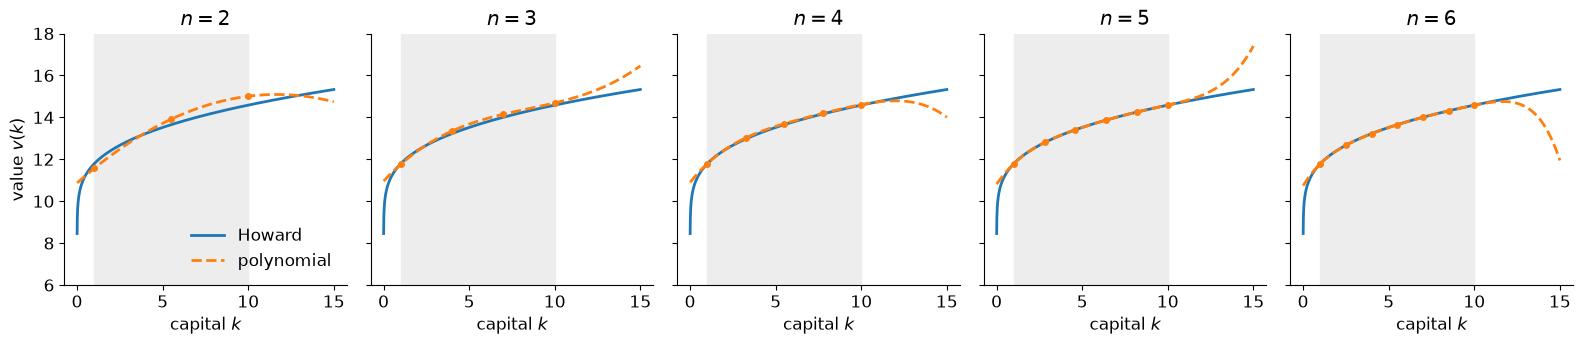

In [9]:
fig, ax = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True)
for axi, n in zip(ax, orders):
    axi.axvspan(params['k_min'], params['k_max'], color='0.93')
    axi.plot(k, v_howard, label='Howard')
    axi.plot(k, P.polyval(k, coef[n]), '--', color='C1', label='polynomial')
    axi.plot(nodes_n[n], P.polyval(nodes_n[n], coef[n]), 'o', color='C1', markersize=4)
    axi.set_title(f'$n={n}$'); axi.set_xlabel('capital $k$')
    axi.set_ylim(6, 18)
ax[0].set_ylabel('value $v(k)$'); ax[0].legend(frameon=False, loc='lower right')
plt.tight_layout();

## Q1.2 Plots of the policy functions

Given the polynomial, we compute the policy on the benchmark grid exactly as in Problem Set 2: for each $k$ we search over $k'$ on the grid, now with the polynomial as the value of tomorrow's capital

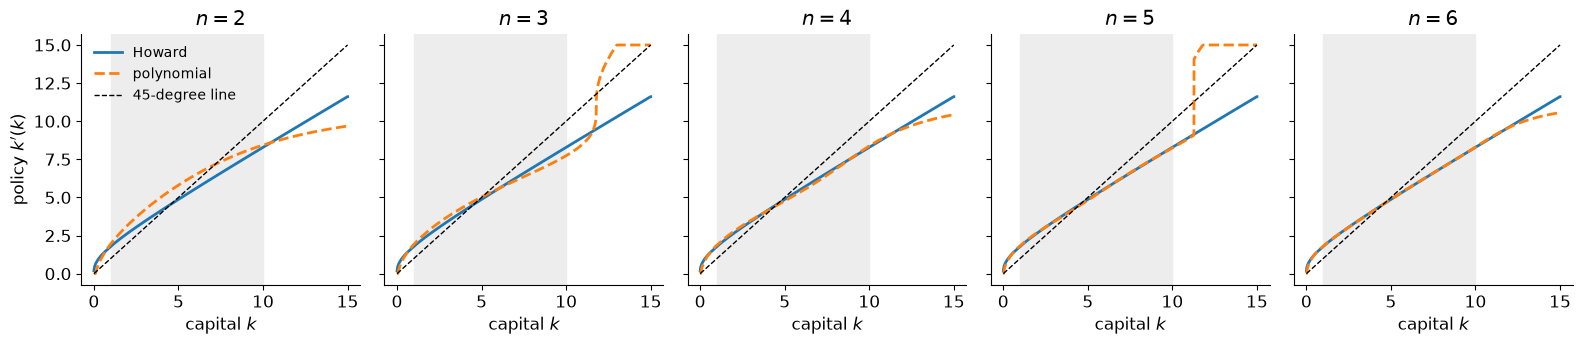

In [10]:
g_poly = {n: bellman(P.polyval(k, coef[n]), k, f, params)[1] for n in orders}

fig, ax = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True)
for axi, n in zip(ax, orders):
    axi.axvspan(params['k_min'], params['k_max'], color='0.93')
    axi.plot(k, k[g_howard], label='Howard')
    axi.plot(k, k[g_poly[n]], '--', color='C1', label='polynomial')
    axi.plot(k, k, 'k--', linewidth=1, label='45-degree line')
    axi.set_title(f'$n={n}$'); axi.set_xlabel('capital $k$')
ax[0].set_ylabel("policy $k'(k)$"); ax[0].legend(frameon=False, loc='upper left', fontsize=10)
plt.tight_layout();

## Q1.3 How large does the order of the polynomial have to be?

Largest absolute errors relative to Howard's algorithm, inside the interval $[1,10]$ spanned by the nodes:

In [11]:
inside = (k >= params['k_min']) & (k <= params['k_max'])
for n in orders:
    err_v = np.max(np.abs(P.polyval(k, coef[n]) - v_howard)[inside])
    err_g = np.max(np.abs(k[g_poly[n]] - k[g_howard])[inside])
    print(f'n = {n}:   value {err_v:.4f}   policy {err_g:.3f}')

n = 2:   value 0.4710   policy 0.939
n = 3:   value 0.1638   policy 0.549
n = 4:   value 0.0582   policy 0.177
n = 5:   value 0.0141   policy 0.066
n = 6:   value 0.0106   policy 0.027


**Comments**
- Inside $[1,10]$ the approximation improves quickly with $n$: from $n=4$ the value function is almost indistinguishable from the benchmark, and the policy is off by less than $0.2$, falling to less than $0.03$ with $n=6$
- The value function is approximated better than the policy: what matters for the policy is the *slope* of $v$, which a polynomial approximates less precisely than its level
- Outside $[1,10]$ the polynomial *extrapolates*, and the approximation deteriorates quickly, especially near $k=0$, where the true $v$ is very steep
- Extrapolation is not confined to the plots: it already happens inside the iteration. At $k=10$, resources are $0.8\cdot10+3\cdot10^{0.3}\approx14$, so Step 3 evaluates the polynomial well above the largest node

# Question 3: an $AK$ model with endogenous labour supply

$$
v(k)=\max_{0\le n<1}\Big\{Ak+\log(1-n)+\beta\, v(kn)\Big\} \tag{5}
$$

- Choosing labour $n$ is the same as choosing tomorrow's capital $k'=kn$, with $0\le k'<k$
- Parameters as in the figure in the solutions: $A=0.5$, $\beta=0.9$
- State space $[0,10]$: capital can only fall, so the state space is invariant (Q3.2 in the solutions)
- Theory (Q3.3–Q3.4 in the solutions): $v$ is increasing and convex; labour supply is zero below the cut-off $k^*=1/(A\beta)$, where $v(k)=Ak$, and increasing in $k$ above it; capital reaches zero in finite time

We solve (5) by VFI on a grid, as in Problem Set 2, and check these results

In [12]:
params3 = dict(A=0.5, beta=0.9,      # model parameters
               k_max=10.0)           # upper bound for capital

k3 = np.linspace(0, params3['k_max'], 1_001)     # grid with step 0.01, now including k = 0
k_star = 1/(params3['A']*params3['beta'])        # labour supply cut-off

## The Bellman operator on a grid

- For each pair $(k_i,k_j)$ of grid points, labour is $n=k_j/k_i$, and the value is $Ak_i+\log(1-k_j/k_i)+\beta v(k_j)$
- Only $k_j<k_i$ is feasible, since $n<1$: all other combinations get $-\infty$
- At $k=0$ the only choice is $k'=0$, with $n=0$ and utility $\log(1)=0$. Unlike in Problem Set 2, $k=0$ can stay on the grid: $v(0)=0$ is finite

In [13]:
def bellman3(v, k, params):
    K, Kp = k[:, None], k[None, :]                                    # rows: k today; columns: k' tomorrow
    n = np.divide(Kp, K, out=np.zeros((len(k), len(k))), where=K > 0)  # labour supply n = k'/k
    feasible = (Kp < K) | ((K == 0) & (Kp == 0))                      # n < 1, and k' = 0 when k = 0
    values = np.where(feasible, params['A']*K + np.log(np.maximum(1 - n, 1e-300)) + params['beta']*v[None, :], -np.inf)
    return values.max(axis=1), values.argmax(axis=1)

def vfi3(k, params, tol, max_iter):
    v = np.zeros(len(k))
    for j in range(max_iter):
        Tv, g = bellman3(v, k, params)
        dist = np.max(np.abs(Tv - v))
        v = Tv
        if dist < tol:
            return v, g, j + 1
    print(f'Warning: no convergence after {max_iter} iterations')
    return v, g, max_iter

v3, g3, iterations = vfi3(k3, params3, tol, max_iter)
kp3 = k3[g3]                                                          # policy k'(k)
n3 = np.divide(kp3, k3, out=np.zeros(len(k3)), where=k3 > 0)          # labour supply n(k) = k'(k)/k
print(f'VFI converged in {iterations} iterations')

VFI converged in 10 iterations


**Why so few iterations?** From any $k\le10$, capital reaches zero within a few periods, and the value at zero, $v(0)=0$, is already right in the initial guess $v_0=0$. So after a few iterations VFI has in effect solved a finite-horizon problem, and the iterates stop changing

## Value function, policy function and labour supply

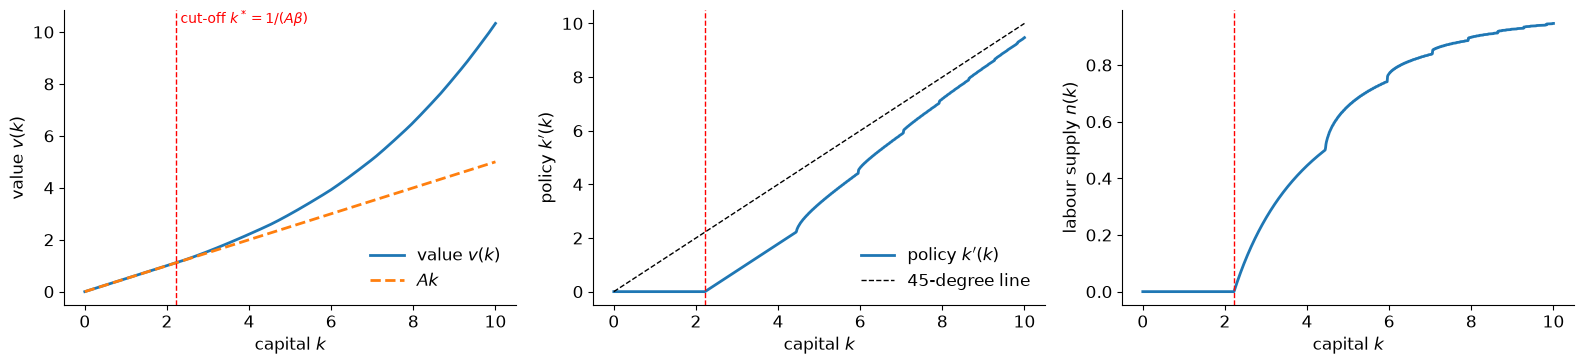

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(k3, v3, label='value $v(k)$')
ax[0].plot(k3, params3['A']*k3, '--', color='C1', label='$Ak$')
ax[0].set_ylabel('value $v(k)$')
ax[1].plot(k3, kp3, label="policy $k'(k)$")
ax[1].plot(k3, k3, 'k--', linewidth=1, label='45-degree line')
ax[1].set_ylabel("policy $k'(k)$")
ax[2].plot(k3, n3)
ax[2].set_ylabel('labour supply $n(k)$')
for axi in ax:
    axi.axvline(k_star, color='red', linestyle='--', linewidth=1)
    axi.set_xlabel('capital $k$')
ax[0].text(k_star, ax[0].get_ylim()[1], ' cut-off $k^*=1/(A\\beta)$', color='red', va='top', fontsize=10)
ax[0].legend(frameon=False, loc='lower right'); ax[1].legend(frameon=False, loc='lower right')
plt.tight_layout();

- Below the cut-off $k^*$ the planner does not work: $n=0$, $k'=0$, and $v(k)=Ak$
- Above $k^*$, labour supply rises with $k$ towards 1, and $v$ bends upwards: it is convex
- **Kinks and small jumps** at $k\approx4.4$, $6.0$, $7.1$, $7.9$, …: from $k\approx4.4$ the planner moves exactly to $k^*$, from $k\approx6.0$ to $k\approx4.4$, from $k\approx7.1$ to $k\approx6.0$, and so on. So at each of these points the number of periods before capital falls below $k^*$, and the planner stops working, changes by one
- The jumps are a feature of the model, not of the grid: on a grid 4 times finer they are at the same points and of the same size. Since $v$ is convex, the objective in (5) is not concave in $n$ and can have two local maxima, and at each jump the optimum switches from one to the other. This is why we cannot rely on first-order conditions here (Q3.4 in the solutions)

## How many periods does the planner work?

For each $k$, we follow the policy function and count the periods in which the planner works, $n>0$, before capital falls below $k^*$

thresholds: 2.23, 4.45, 5.96, 7.06, 7.93, 8.65, 9.28, 9.84


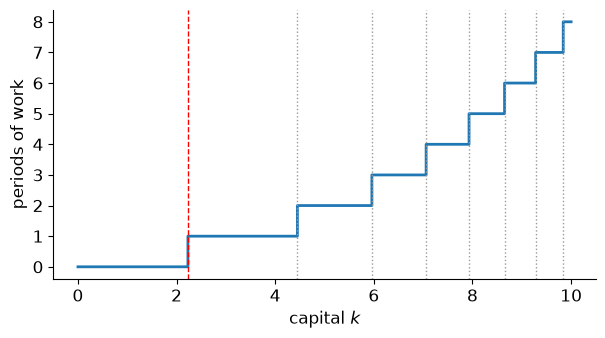

In [15]:
def working_periods(g, k, k_star):
    m = np.zeros(len(k), dtype=int)
    for i in range(len(k)):
        j = i
        while k[j] > k_star:          # the planner works in this period
            j = g[j]
            m[i] += 1
    return m

m3 = working_periods(g3, k3, k_star)
thresholds = [k3[np.argmax(m3 >= j)] for j in range(1, m3.max() + 1)]   # first k with j periods of work

plt.plot(k3, m3, drawstyle='steps-post')
for x in thresholds[1:]:
    plt.axvline(x, color='0.6', linestyle=':', linewidth=1)
plt.axvline(k_star, color='red', linestyle='--', linewidth=1)
plt.yticks(range(m3.max() + 1))
plt.xlabel('capital $k$'); plt.ylabel('periods of work');
print('thresholds:', ', '.join(f'{x:.2f}' for x in thresholds))

The kinks and jumps in the policy are at these thresholds. **Why?**
- **With one period of work left, leisure is fixed in units of capital.** In terms of $k'=kn$, the first-order condition is $1/(k-k')=\beta v'(k')$, where $k-k'=k(1-n)$ is the capital used up as leisure. If the planner does not work tomorrow, $v'(k')=A$, so $k-k'=1/(\beta A)=k^*$: between $k^*$ and $2k^*\approx4.44$ the policy is $k'=k-k^*$, a line with slope 1
- **Each extra period of work makes capital more valuable.** Capital reproduces itself through labour, $k'=kn$: more capital makes work more productive, and more work leaves more capital. So the more periods ahead in which the planner works, the more an extra unit of capital today is worth. Each time $k$ crosses a threshold, one more period of work is added, and $v$ becomes more convex
- **Saving just past a threshold does not pay.** Just above a threshold, the value of an extra unit of capital tomorrow rises faster than its cost in leisure today, so the objective is locally convex in $k'$. These are increasing returns, as with a fixed cost: either stop just below the threshold, or commit to one more period of work and save clearly past it. At $k\approx5.96$ the two options give almost the same value, and as $k$ crosses this point the optimal $k'$ jumps from about $4.42$ to about $4.53$
- At the first threshold, $2k^*\approx4.44$, the increase in convexity is too small to make the objective convex, so the policy has only a kink
- **A richer planner works more.** Consumption $Ak$ is fixed by today's capital and utility is linear in it, so there is no income effect pushing towards leisure, while capital raises the return to work: one unit of labour produces $k$ units of capital

## Checking the theory

In [16]:
below = k3 <= k_star
print(f'largest |v(k) - Ak| for k <= k*:      {np.max(np.abs(v3 - params3["A"]*k3)[below]):.1e}')
print(f'first grid point with n > 0:         {k3[np.argmax(n3 > 0)]:.2f}   (k* = {k_star:.4f})')
print(f'v convex (smallest 2nd difference):  {np.min(np.diff(v3, 2)):.1e}')
print(f'n nondecreasing (smallest change):   {np.min(np.diff(n3)):.1e}')

largest |v(k) - Ak| for k <= k*:      0.0e+00
first grid point with n > 0:         2.23   (k* = 2.2222)
v convex (smallest 2nd difference):  -2.2e-16
n nondecreasing (smallest change):   0.0e+00


- $v(k)=Ak$ exactly below the cut-off, and labour supply becomes positive at the first grid point above $k^*=2.22$
- $v$ is convex: its second differences are nonnegative, up to rounding errors of order $10^{-16}$. It is linear below $k^*$ and strictly convex above it
- Labour supply is nondecreasing in $k$, and increases towards 1 as $k$ grows

## Simulations: capital reaches zero in finite time

Starting from $k_0\in\{3,\ 6,\ 10\}$, we follow the policy function for 12 periods. Since $k'$ is on the grid, we can follow the grid indices exactly, with no interpolation

k0 =  3: capital is zero from period 2
k0 =  6: capital is zero from period 4
k0 = 10: capital is zero from period 9


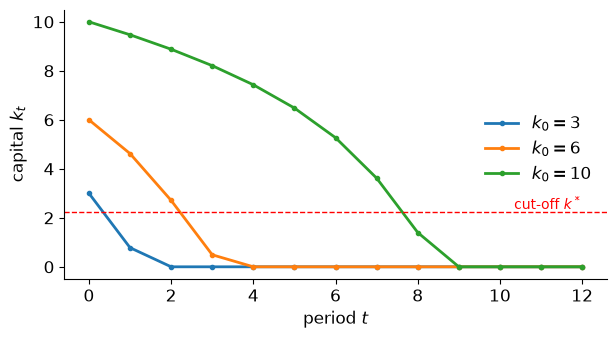

In [17]:
T = 12
for k0 in [3, 6, 10]:
    i = np.argmin(np.abs(k3 - k0))                 # grid index of k0
    path = [k3[i]]
    for t in range(T):
        i = g3[i]
        path.append(k3[i])
    path = np.array(path)
    plt.plot(range(T + 1), path, marker='o', markersize=3, label=f'$k_0={k0}$')
    print(f'k0 = {k0:>2}: capital is zero from period {np.argmax(path == 0)}')
plt.axhline(k_star, color='red', linestyle='--', linewidth=1)
plt.text(T, k_star, 'cut-off $k^*$', color='red', va='bottom', ha='right', fontsize=10)
plt.xlabel('period $t$'); plt.ylabel('capital $k_t$'); plt.legend(frameon=False, loc='lower right', bbox_to_anchor=(1, 0.3));

- Capital falls every period, and faster and faster: at high $k$ the planner works a lot, $n$ close to 1, and as capital falls labour supply falls too
- Once capital is below $k^*$, the planner stops working, and capital is zero from the next period onward
- **Intuition:** the first unit of labour costs 1 in utility and produces $k$ units of capital, worth $\beta Ak$ next period, so working pays only if $k>1/(A\beta)$. With full depreciation, consumption $Ak$ is fixed by today's capital, so the only reason to work is to keep capital for tomorrow

# Beyond the problem set: why do odd degrees go wrong in Question 1?

With $n=3$ and $n=5$ the policy jumps above the 45-degree line at high $k$, and capital runs off to the edge of the grid: the approximation creates a spurious, unstable second steady state. With even $n$ this does not happen. Look at the sign of the leading coefficient $a_n$:

In [18]:
for n in orders:
    print(f'n = {n}:   a_n = {coef[n][-1]: .2e}')

n = 2:   a_n = -3.11e-02
n = 3:   a_n =  3.28e-03
n = 4:   a_n = -4.44e-04
n = 5:   a_n =  7.02e-05
n = 6:   a_n = -1.19e-05


- **Odd $n$, $a_n>0$:** the polynomial eventually becomes increasing and convex. A convex continuation value rewards saving more and more at the margin, so the planner saves almost everything
- **Even $n$, $a_n<0$:** the polynomial eventually becomes decreasing and concave. The policy bends below the true one at high $k$: wrong, but less harmful, since it stays below the 45-degree line
- **Why the sign alternates:** with exactly $n+1$ nodes, $a_n$ equals $v^{(n)}(\xi)/n!$ for some $\xi\in[1,10]$. The value function behaves like a logarithm, whose derivatives alternate in sign: the $n$-th derivative of $\log(k)$ is $(-1)^{n-1}(n-1)!/k^n$
- **The root of the problem:** no polynomial of degree two or higher is increasing and concave on all of $[0,\infty)$, since its derivative would then be a nonincreasing polynomial bounded below by zero, hence constant. So extrapolation always fails, and the sign of $a_n$ only decides how
- **What makes this worrying:** nothing warns us. The coefficients converge and the value function looks reasonable, but the policy, which determines the dynamics, is qualitatively wrong

# Beyond the problem set: better nodes and better polynomials

- **Do not extrapolate:** restrict the search in Step 3 to $k'\in[1,10]$, the interval spanned by the nodes, and use the approximation only there. Here this restriction does not bind at the optimum, since the policy maps $[1,10]$ into itself
- **Conditioning:** the powers $1,k,k^2,\dots$ become nearly collinear as $n$ grows, so the Vandermonde matrix is badly conditioned and the coefficients are sensitive to small errors. Its condition number is about $10^2$ with $n=2$ and $10^8$ with $n=6$
- **Chebyshev polynomials and Chebyshev nodes:** a basis of polynomials that are orthogonal, and nodes that cluster near the ends of the interval, solve both problems and avoid the large errors near the ends that evenly spaced nodes produce (Runge's phenomenon). This is the standard choice in practice (Judd 1998, Chapter 6)
- **Shape-preserving approximation:** for example, piecewise polynomials (splines) that are restricted to be increasing and concave (Judd 1998, Chapter 6)

# Takeaways

- **Parametric approximation:** describe $v$ by a few coefficients instead of its values at many grid points, and evaluate the Bellman equation only at a few nodes
- **Fitting is a linear problem:** with $n+1$ nodes the polynomial interpolates the points; with more nodes we fit it by least squares
- **Accuracy inside the nodes is good** with a moderate order, $n=4$ to $6$ here
- **Outside the nodes, polynomials extrapolate badly**, and the errors feed back into the iteration. With odd $n$ the result is qualitatively wrong, and nothing warns us
- **Check numerical results against theory, and theory against numerical results:** in Question 3 the grid solution reproduces the cut-off $k^*=1/(A\beta)$, $v(k)=Ak$ below it, the convexity of $v$, and capital reaching zero in finite time

**References**

Judd, K. L. (1998): *Numerical Methods in Economics*. Cambridge, MA: MIT Press.

**Running this notebook**

Times are for a MacBook Air (Apple M2, 8 GB of RAM), where the whole notebook takes about 10 seconds. The notebook needs less than 1 GB of free memory